# Chemeleon experiment results analysis 

(This is the main notebook for the final analysis after running all Chemeleon experiments on HPC)

In [3]:
import pandas as pd
import numpy as np
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt


In [4]:
results_df = pd.read_csv("results/chemeleon/run2_results_hpc/all_runs2.csv")
per_target_results = pd.read_csv("results/chemeleon/run2_results_hpc//per_target2.csv")

results_df = results_df.fillna('NA')
per_target_results = per_target_results.fillna("NA")

results_df.head(2)

,task,exp,seed,freeze_encoder,encoder_lr,head_lr,readout,hidden_dim,num_layers,dropout,...,lr_factor,lr_patience,val_score,baseline_score,best_epoch,epochs_run,final_score,train_loss_first,train_loss_last,overrides
0,classification,r2/01_frozen_linear,42,True,0.00001,0.001,linear,NA,NA,NA,...,0.5,2,0.149956,0.0,20,20,0.149956,0.533532,0.428361,model=chemeleon task=classification readout=li...
1,classification,r2/01_frozen_linear,43,True,0.00001,0.001,linear,NA,NA,NA,...,0.5,2,0.147442,0.0,19,20,0.103199,0.534993,0.427529,model=chemeleon task=classification readout=li...


In [5]:
per_target_results.head(2)

,task,exp,seed,target,MCC,AUROC,AP,n,positive_fraction,MAE,R2,ST-RAE
0,classification,r2/01_frozen_linear,42,CYP2D6_is_TDI,0.10759,0.685011,0.46434,230,0.273913,NA,NA,NA
1,classification,r2/01_frozen_linear,42,CYP3A4_is_TDI,0.192322,0.76887,0.450967,530,0.203774,NA,NA,NA


## Overall experiments summary

In [6]:
results_df.groupby("task").agg(
    runs = ("val_score", "size"),
    n_config = ("exp", "nunique"),
    n_seeds = ('seed', 'nunique'),
    min_score = ('val_score', 'min'),
    max_score = ("val_score",'max'),
    mean_score = ('val_score',"mean"),
    baseline_mean = ('baseline_score', 'mean')
)

,runs,n_config,n_seeds,min_score,max_score,mean_score,baseline_mean
task,,,,,,,
classification,39,13,3,0.143572,0.314833,0.264174,0.000000
regression,39,13,3,0.703773,0.750938,0.727459,0.983028


our experiments consisted of 78 runs - 39 per task with 13 unique configurations (repeated for each of the 3 seeds)

For classification we see quite a big spread of validation scores with min being 0.14 and max being 0.31. For regression the difference is not that significant. 

For both tasks Chemeleon scores are better than the naive baseline predictor.

## How the results between configurations differ?

Since in the current setup the model is non deterministic we repeated each experiment (configuration) on 3 seeds. Now we will test if the differences between configurations are significant, or are they comparable to the noise (as changing seeds). 

Anova one way test - H0: the distributions dont differ significantly.

In [7]:
regression_results = results_df[results_df['task']=='regression']
classification_results = results_df[results_df['task']=='classification']

In [8]:
# regression ANova test

val_scores = []
unique_experiments = regression_results['exp'].unique()

for exp in unique_experiments:
    exp_column = regression_results[regression_results['exp']==exp]['val_score']
    val_scores.append(exp_column)
test = stats.f_oneway(*val_scores)
p_val = test.pvalue
print(p_val)

0.8011918700100025


For regression the p value of annova test is 0.8 > 0.05 menaing we cannot discard H0 hypothesis. There are no signs of the validation scores being sgnificantly different from each other on different configurations. 

In [9]:
# classif ANova test

val_scores = []
unique_experiments = classification_results['exp'].unique()

for exp in unique_experiments:
    exp_column = classification_results[classification_results['exp']==exp]['val_score']
    val_scores.append(exp_column)
test = stats.f_oneway(*val_scores)
p_val = test.pvalue
print(round(p_val,5))

0.0


For classification p value = 0, which is a sign that different configurations produce significanly different validation scores.

## Best run and best configuration

#### Best single run

In [10]:
best_regression_score = regression_results['val_score'].min()
print("Best regression score : ", best_regression_score)

best_classification_score = classification_results['val_score'].max()
print("Best classification score: ", best_classification_score)

Best regression score :  0.7037734068569841
Best classification score:  0.3148326841405417


In [11]:
config_params = ['freeze_encoder', 'encoder_lr', 'head_lr', 'readout','hidden_dim', 'dropout','best_epoch','head_only_epochs']

In [12]:
best_reg_run = regression_results[regression_results['val_score']==best_regression_score][config_params]
best_reg_run

,freeze_encoder,encoder_lr,head_lr,readout,hidden_dim,dropout,best_epoch,head_only_epochs
48,False,0.00001,0.001,mlp,512.0,0.0,4,0


In [13]:
best_classif_run = classification_results[classification_results['val_score']== best_classification_score][config_params]
best_classif_run

,freeze_encoder,encoder_lr,head_lr,readout,hidden_dim,dropout,best_epoch,head_only_epochs
11,False,0.00001,0.001,mlp,512.0,0.0,7,0


The configuration of the best run is the same for classification and regression - MLP head, end to end finetuning with the same learning rates. Both of those runs reached their best score quite early during the training (epochs 4 and 7).

#### Best configurations

In [14]:
regression_best_config = regression_results.groupby('exp').val_score.agg('mean').idxmin()
print("regression best config (mean score)", regression_best_config)
regression_best_config_score = regression_results[regression_results['exp']==regression_best_config]['val_score'].mean()
print("score on the best config : ", regression_best_config_score)

print( " ---------------------------------------------------- ")
classif_best_config = classification_results.groupby('exp').val_score.agg("mean").idxmax()
print("Classification best config (mean score): ", classif_best_config)
classification_best_config_score = classification_results[classification_results['exp']==classif_best_config]['val_score'].mean()
print("score on the best config:", classification_best_config_score)

regression best config (mean score) r2/04_dropout03_mlp
score on the best config :  0.718461905691759
 ---------------------------------------------------- 
Classification best config (mean score):  r2/04_dropout01_mlp
score on the best config: 0.2918039554115906


In [15]:
# hyperparams of these configurations

regression_results[regression_results['exp'] == regression_best_config].iloc[0][config_params]

freeze_encoder       False
encoder_lr          0.0001
head_lr              0.001
readout                mlp
hidden_dim           512.0
dropout                0.3
best_epoch               6
head_only_epochs         5
Name: 66, dtype: object

In [16]:
classification_results[classification_results['exp']==classif_best_config].iloc[0][config_params]

freeze_encoder       False
encoder_lr          0.0001
head_lr              0.001
readout                mlp
hidden_dim           512.0
dropout                0.1
best_epoch              13
head_only_epochs         5
Name: 24, dtype: object

although the best run was on the same configuration, when looking at the mean scores on all seeds we see small differences. The best readout is still MLP with 512 neurons, but encoder learning rate is now 0.0001 with the warmup technique instead of end to end finetuning from the begnning.

**Best configuration improvement from the  naive baseline**

In [17]:
baseline_best_config_reg = regression_results[regression_results['exp']==regression_best_config]['baseline_score'].mean()
print("naive baseline - validation score (avg) on the best configuration for regression: ", baseline_best_config_reg-regression_best_config_score)

baseline_best_config_classif = classification_results[classification_results['exp']==classif_best_config]['baseline_score'].mean()
print("naive baseline - validation score (avg) on the best config for classification : ", baseline_best_config_classif - classification_best_config_score)

naive baseline - validation score (avg) on the best configuration for regression:  0.2645658975387615
naive baseline - validation score (avg) on the best config for classification :  -0.2918039554115906


# All configurations analysis 


Now we want to see how the choice of readout and freezing strategy influences the performance

In [73]:
def add_strategy(row):
    if row['freeze_encoder']==True:
        return "frozen"
    elif row['head_only_epochs']>0:
        return "warmup"
    else:
        return "end2end"

regression_results['strategy'] = regression_results.apply(add_strategy, axis=1)
classification_results['strategy'] = classification_results.apply(add_strategy, axis=1)

C:\Users\rogal\AppData\Local\Temp\ipykernel_11364\1716014096.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  regression_results['strategy'] = regression_results.apply(add_strategy, axis=1)
C:\Users\rogal\AppData\Local\Temp\ipykernel_11364\1716014096.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  classification_results['strategy'] = classification_results.apply(add_strategy, axis=1)


In [74]:
regression_results.head(1)

,task,exp,seed,freeze_encoder,encoder_lr,head_lr,readout,hidden_dim,num_layers,dropout,...,val_score,baseline_score,best_epoch,epochs_run,final_score,train_loss_first,train_loss_last,overrides,strategy,method
39,regression,r2/01_frozen_linear,42,True,0.00001,0.001,linear,NA,NA,NA,...,0.744778,0.983028,17,20,0.7581,0.938563,0.51874,model=chemeleon task=regression readout=linear...,frozen,freezed + linear


In [75]:
regression_results['method'] = regression_results['strategy'] + " + " + regression_results['readout']
classification_results['method'] = classification_results['strategy'] + " + " + classification_results['readout']

C:\Users\rogal\AppData\Local\Temp\ipykernel_11364\923578401.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  regression_results['method'] = regression_results['strategy'] + " + " + regression_results['readout']
C:\Users\rogal\AppData\Local\Temp\ipykernel_11364\923578401.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  classification_results['method'] = classification_results['strategy'] + " + " + classification_results['readout']


In [85]:
palette = {
    "frozen + linear": "#4477AA",
    "frozen + mlp": "#ABCDE0",
    "end2end + linear": "#508A68",
    "end2end + mlp": "#9DD1B1",
    "warmup + linear": "#AA3377",
    "warmup + mlp": "#E0ABD8"
}


short_labels = {
    'r2/01_frozen_linear' : "frozen_linear",
    'r2/01_frozen_mlp' : " frozen_mlp",
    'r2/02_unfrozen_linear' : "unfozen_linear",
    'r2/02_unfrozen_mlp' : "unfrozen_mlp",
    'r2/03_warmup_lr1e-4_linear': "warmup_linear_lr1e-4",
    'r2/03_warmup_lr1e-4_mlp': "warmup_mlp_lr1e-4", 
    'r2/03_warmup_lr1e-5_linear': "warmup_linear_lr1e-5",
    'r2/03_warmup_lr1e-5_mlp' : "warmup_mlp_lr1e-5",
    'r2/04_dropout01_mlp': "mlp_droupout01",
    'r2/04_dropout03_mlp': "mlp_droupout03", 
    'r2/05_wd1e-2_mlp': "mlp_weightdecay1e-2", 
    'r2/05_wd1e-4_mlp': "mlp_weightdecay1e-4",
    'r2/06_reduce_lr_mlp': "mlp_reduce_lr"
}


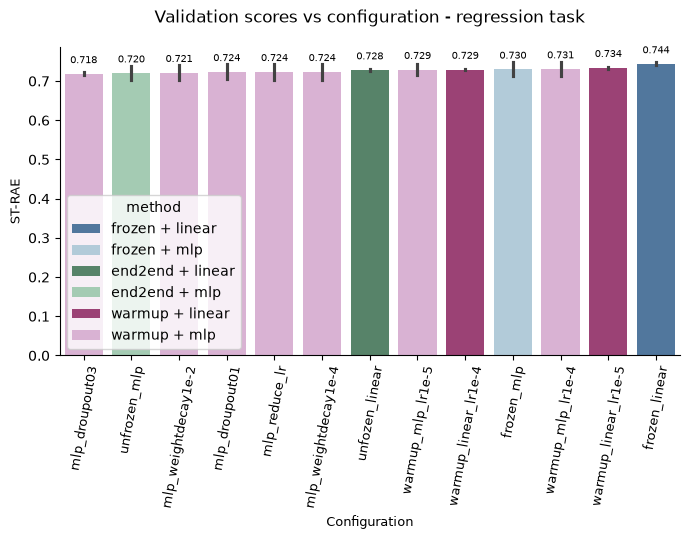

In [86]:
order = regression_results.groupby('exp')['val_score'].mean().sort_values().index.to_list()

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=regression_results, x='exp', y='val_score',errorbar='sd',hue='method', order=order,palette=palette, ax=ax )

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=6, fontsize=7)
labels = [short_labels.get(x, x) for x in order]

ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=80, fontsize=9)

ax.set_xlabel("Configuration", fontsize=9)
ax.set_ylabel("ST-RAE", fontsize = 9)
ax.set_title("Validation scores vs configuration - regression task", pad=18)
sns.despine(ax=ax)


For regression task the worst performing configurations were frozen and warmup linear and the best were warmup/end to end MLP heads. We see that end to end linear configuration was outperforming some MLP heads.

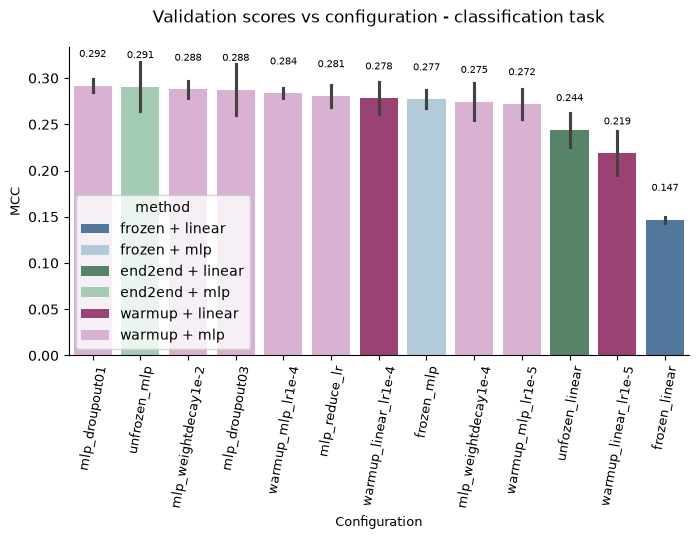

In [91]:
order = classification_results.groupby('exp')['val_score'].mean().sort_values(ascending=False).index.to_list()

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=classification_results, x='exp', y='val_score',errorbar='sd',hue='method', order=order,palette=palette, ax=ax )

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=19, fontsize=7)
labels = [short_labels.get(x, x) for x in order]

ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=80, fontsize=9)

ax.set_xlabel("Configuration", fontsize=9)
ax.set_ylabel("MCC", fontsize = 9)
ax.set_title("Validation scores vs configuration - classification task", pad=18)
sns.despine(ax=ax)


For classification the best results are also for warmup and end to end MLP heads. The frozen linear is significantly lower than other configurations. Here the warmup linear was also outperforming some MLP configurations.

**COnclusions**:

1. MLP readout is the winning architecture for both tasks

2. End to end and warmup strategies outperform freezing - the model benefits from some additional training on the new data

3. frozen linear head and warmup with very small lr are the 2 worst configurations. 

4. For both tasks the frozen architecture is the underperforming one. 

Does unfreezing help ? (overall scores comparison - on all configurations)

In [96]:
print(regression_results.groupby(['strategy','readout']).val_score.agg('mean'))

print("------------------------")

print(classification_results.groupby(['strategy', 'readout']).val_score.agg('mean'))

strategy  readout
end2end   linear     0.728117
          mlp        0.720371
frozen    linear     0.743668
          mlp        0.729893
warmup    linear     0.731794
          mlp        0.724475
Name: val_score, dtype: float64
------------------------
strategy  readout
end2end   linear     0.244072
          mlp        0.290569
frozen    linear     0.146990
          mlp        0.277317
warmup    linear     0.248566
          mlp        0.282597
Name: val_score, dtype: float64


For regression the scores are very similar regardless of the strategy, suggesting that frozen vs end to end does not change the results much (is aligned with the ANOVA test finding as well).

However, for classification we see large differences, specifically with different strategies on linear head, where end to end/warmup is much better than freezing. 

**Conclusion** : For classification unfreezing the encoder makes the biggest difference, especially for linear head meaning that MLP is able to better use the pre trained representations, while linear head highly benefits from additional training of the encoder.

## Best training epoch analysis

C:\Users\rogal\AppData\Local\Temp\ipykernel_11364\2854056878.py:4: UserWarning: The palette list has more values (9) than needed (2), which may not be intended.
  sns.histplot(


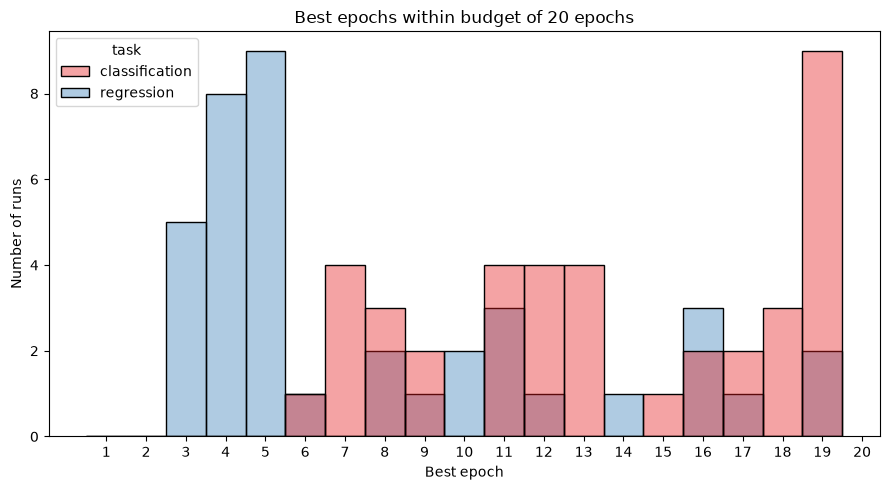

In [118]:
fig, ax = plt.subplots(figsize=(9, 5))
palette = sns.color_palette("Set1")

sns.histplot(
    data=results_df,
    x="best_epoch",
    hue="task",
    bins=range(1, 21),
    alpha=0.4,
    ax=ax,
    palette = palette
)

ax.set_xticks(np.arange(1.5, 21,1))
ax.set_xticklabels(range(1, 21))
ax.set_xlabel("Best epoch")
ax.set_ylabel("Number of runs")
ax.set_title("Best epochs within budget of 20 epochs")

plt.tight_layout()
plt.show()

For regression the model tends to overfit quickly - the best epochs are usually very early (3-5 epoch), while for classification many runs seem to be terminated too quickly. (20 epochs may not be enough)

Lets see the configurations where the best epoch was 19:

In [119]:
classification_results[classification_results['best_epoch']==19]['exp']

1            r2/01_frozen_linear
2            r2/01_frozen_linear
6          r2/02_unfrozen_linear
7          r2/02_unfrozen_linear
19    r2/03_warmup_lr1e-5_linear
27           r2/04_dropout03_mlp
Name: exp, dtype: object

This happens mostly for linear heads (which had poor results) and in one run for the MLP head. 

We repeated the experiments : r2/02_unfrozen_linear (from the experiments above), and r2/02_dropout01_mlp (as the best configuration for classification)